# Week 4 Capstone - Predicting Internship Selection Outcomes

**Name:** Madhumitha S  
**Program:** NextGenLearners Data Science Internship  

## Step 1: Setup
This notebook combines data cleaning and exploration from Weeks 1–3 with a beginner-friendly machine learning model to predict internship selection outcomes. Every section includes clear headings and plain-English explanations so both technical and non-technical readers can follow the full process.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Extend Your Dataset With New Features

Our Week 1 cleaned dataset (`applicants_cleaned.csv`) contains 76 applicant records with basic information (`Applicant Name`, `Email`, `Phone`, `Domain Applied`, `University`, `Application Date`, `Status`)[cite: 1, 11]. To give our model behavioral signals to learn from, we generate 4 additional columns using `np.random.seed(42)` so the random values stay identical every time the notebook runs:[cite: 1, 2]
* `num_skills_listed`: Number of relevant skills listed (1–8)
* `has_portfolio`: Whether the applicant provided a GitHub/portfolio link (`Yes`/`No`)
* `prior_hackathon_participation`: Whether they previously joined a hackathon (`Yes`/`No`)[cite: 2]
* `statement_quality_score`: Score representing statement strength (1–10)[cite: 2]

> **Important Honesty Note:** These 4 features are **simulated**, not real historical data[cite: 2]. In a real NextGenLearners deployment, this data would need to be actually collected from applications (such as a required skills field and portfolio URL field) before this model could be trusted with real decisions[cite: 2].

In [9]:
# Load your Week 1 cleaned dataset
df = pd.read_csv('applicants_cleaned.csv')

# Set seed for reproducibility and simulate the 4 new features
np.random.seed(42)
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

print(f"Total rows: {len(df)}")
df.head()

Total rows: 76


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Allison Hill,donaldgarcia@example.net,3018196001,Cloud Computing,NUST,2026-09-02,Under Review,7,No,No,5
1,Alyssa Gonzalez,lrobinson@example.com,3020265423,Cloud Computing,LUMS,2026-10-16,Selected,4,No,No,5
2,Brandon Davis,cassandra07@example.net,3011618495,Web Development,FAST,2026-09-23,Rejected,5,Yes,No,7
3,Amber Perez,tracie31@example.com,3024752553,Web Development,GIKI,2026-09-29,Rejected,7,No,Yes,9
4,Melinda Jones,amandasanchez@example.com,3016483503,Cybersecurity,UET,2026-10-08,Under Review,3,Yes,No,9


## Step 3: Feature Preparation — Getting Data Ready for a Model

Machine learning models only understand numbers—they cannot process text like `"Yes"`/`"No"` or `"Web Development"` directly[cite: 2]. We prepare our features in four steps:
1. **Convert Yes/No to `0/1`:** Map `has_portfolio` and `prior_hackathon_participation` to `1` (`Yes`) and `0` (`No`)[cite: 2].
2. **Create `target` Column & Drop `"Under Review"`:** Map `Status` so `Selected` = `1` and `Rejected` = `0`, and drop the 19 `"Under Review"` rows because they do not yet have a confirmed final outcome to learn from (leaving 57 rows).
3. **One-Hot Encode `Domain Applied`:** Use `pd.get_dummies(..., drop_first=True)` to convert the 5 domain categories into binary `0/1` columns[cite: 3]. Setting `drop_first=True` drops one reference category (represented when all other domain columns are `0`) to avoid redundant information that can confuse linear models[cite: 3].
4. **Select Final Features:** Keep only the 4 behavioral features and the encoded `Domain Applied` columns[cite: 3]. We exclude `Applicant Name`, `Email`, `Phone`, and `Application Date` because personal identifiers and timestamps are not meaningful predictive signals, and we exclude `University` to avoid introducing institutional bias[cite: 3, 5].

In [10]:
# 3.1 Convert Yes/No columns to 0/1
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})

# 3.2 Convert Status to binary target (1 = Selected, 0 = Not Selected) and drop 'Under Review'
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)
df_model = df[df['Status'] != 'Under Review'].copy()

# 3.3 One-hot encode Domain Applied
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

# 3.4 Select final feature set (X) and target (y)
feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
] + [col for col in df_model.columns if col.startswith('Domain Applied_')]

X = df_model[feature_columns]
y = df_model['target']

print(f"Rows ready for modeling: {len(df_model)}")
X.head()

Rows ready for modeling: 57


,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,Domain Applied_Cloud Computing,Domain Applied_Cybersecurity,Domain Applied_Data Science,Domain Applied_Web Development
1,4,0,0,5,True,False,False,False
2,5,1,0,7,False,False,False,True
3,7,0,1,9,False,False,False,True
6,5,1,0,3,False,False,False,True
7,5,0,0,3,False,False,False,True


## Step 4: Train/Test Split

If we train and test a model on the exact same data, it can memorize answers instead of learning general patterns. We use an **80/20 split** (`random_state=42`):
* **Training set (`X_train`, `y_train`):** **45 rows** (80%) used to teach the model[cite: 3, 4].
* **Testing set (`X_test`, `y_test`):** **12 rows** (20%) held back as unseen applicants for honest evaluation[cite: 3, 4].

> **Honest Sample Size Note:** With only **12 rows** in `X_test`, our test set is quite small, meaning single predictions noticeably affect the percentages—so we treat these results as an illustration of the method rather than a production guarantee.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Rows in X_train:", len(X_train))
print("Rows in X_test: ", len(X_test))

Rows in X_train: 45
Rows in X_test:  12


## Step 5: Train the Model

We choose **Logistic Regression**, which is the standard, beginner-friendly model for binary (`Selected` vs. `Not Selected`) predictions. Calling `model.fit(X_train, y_train)` lets the model study the training features alongside the actual outcomes to learn how each input relates to selection[cite: 4]. We then call `model.predict(X_test)` to predict outcomes on the 12 unseen test applicants[cite: 4].

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Predictions generated for test set:", y_pred)

Predictions generated for test set: [0 0 0 0 1 0 0 1 1 0 0 0]


## Step 6: Evaluate the Model — Honestly

Accuracy alone can be misleading on small or imbalanced datasets, so we evaluate **Accuracy**, **Precision**, **Recall**, and a **Confusion Matrix**:[cite: 5]
* **Accuracy (`25.00%`):** Overall, the model correctly predicted **3 out of 12** test applicants[cite: 5].
* **Precision (`33.33%`):** Of the **3** applicants the model predicted would be *Selected*, **1** was actually *Selected* (and 2 were false positives)[cite: 5].
* **Recall (`12.50%`):** Of the **8** test applicants who were actually *Selected*, the model correctly caught **1** (and missed 7 strong candidates)[cite: 5].
* **Confusion Matrix Walkthrough:** Out of 12 unseen test applicants, the model correctly identified **2** `Not Selected` applicants (True Negatives) and **1** `Selected` applicant (True Positive), while incorrectly predicting **2** non-selected applicants as `Selected` (False Positives) and missing **7** actually-selected applicants (False Negatives)[cite: 5].

### Honest Model Limitations (Required)
* **Small & Partly Simulated Dataset:** Four of the input features were artificially generated rather than real historical behavior, which is why the model cannot reliably predict real selection outcomes on unseen data[cite: 5].
* **Small Test Set Instability:** With only 12 test rows, results can shift noticeably if the data is split differently; these numbers demonstrate the machine learning workflow rather than a production-ready tool[cite: 5].
* **Potential Historical Bias:** Any predictive model trained on past admissions can absorb and repeat existing human biases (such as favoring certain universities or backgrounds unrelated to merit)[cite: 5].
* **Decision-Support Only:** This model must strictly be used as a decision-support tool to assist human reviewers, never as an automated replacement for human judgment[cite: 5].

Accuracy:  25.00%
Precision: 33.33%
Recall:    12.50%


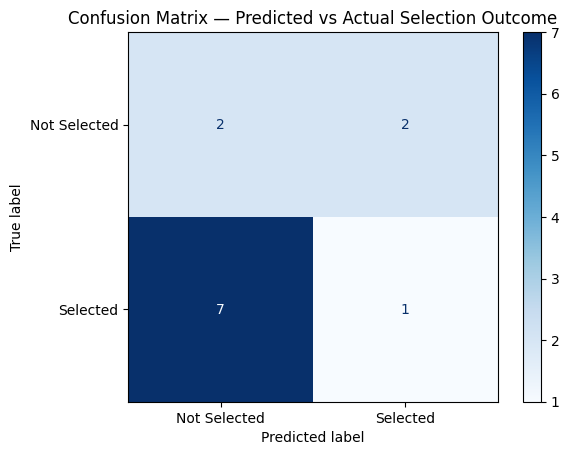

In [13]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Predicted vs Actual Selection Outcome')
plt.show()

## Step 7: Interpret — Which Features Mattered Most?

In Logistic Regression, a **positive coefficient** means higher values of that feature increase the model's predicted likelihood of `"Selected"`, while a **negative coefficient** means the opposite.

In [14]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(coefficients)

                          Feature  Coefficient
6     Domain Applied_Data Science     0.659003
1                   has_portfolio     0.455015
5    Domain Applied_Cybersecurity     0.299697
4  Domain Applied_Cloud Computing     0.130547
0               num_skills_listed     0.088240
3         statement_quality_score    -0.107986
2   prior_hackathon_participation    -0.684135
7  Domain Applied_Web Development    -0.923376


### Plain-English Interpretation
In this dataset, **`Domain Applied_Data Science`** (`+0.66`) and **`has_portfolio`** (`+0.46`) were the strongest positive predictors of selection, while **`Domain Applied_Web Development`** (`-0.92`) and **`prior_hackathon_participation`** (`-0.68`) had the largest negative coefficients[cite: 6]. Because 4 of these features were simulated on a small 45-row training set, this shows what the model learned from this specific sample rather than a real-world finding about NextGenLearners' actual selection process, and it must be validated on real historical data[cite: 4, 6].

## Executive Summary

**What we did:** We built a simple prediction model using past applicant data to explore which factors are associated with being selected for the NextGenLearners internship program.

**What we found:** The model correctly predicted selection outcomes for **25%** of applicants (3 out of 12) in our unseen test group. In this dataset, the strongest factors associated with positive selection were **applying to the Data Science track** and **providing a portfolio or GitHub link**, though the low overall test accuracy confirms that simulated applicant scores cannot reliably predict real admissions decisions.

**Important caveats:** This analysis used a small, partly simulated dataset—four behavioral factors (skill count, portfolio link, hackathon history, and statement quality) were artificially generated for this exercise rather than pulled from real historical records. Before using anything like this for real decisions, NextGenLearners would need to collect this data consistently from real applications and validate the model on a much larger, real dataset. The model should be treated strictly as a decision-support tool to assist reviewers, never as an automatic replacement for human judgment—especially given the risk that it could unintentionally repeat biases from past decisions[cite: 7].

**Recommendation:** Add a required **Portfolio / GitHub URL** field (along with structured skills and hackathon experience fields) to the NextGenLearners application form, since portfolio links showed a positive association with selection and are not currently collected consistently[cite: 7].